# M1 physics tour - simplified Viking lander on Mars

Explore the simulator and check its physics. **All the code lives in the `lander` package; this notebook only
calls it and plots.** Run it in VS Code with the `.venv` kernel, or headless:

```
.venv\Scripts\python -m nbconvert --to notebook --execute --inplace notebooks/m1_physics_tour.ipynb
```

Every number comes from `.env` (value | unit | status | source); `docs/env_variables.md` explains each one.
Simplified vehicle (brief D15): rigid legs that break above 3.34 m/s down or 1.22 m/s sideways, CG fixed on the
centre line, no roll jets, and the agent cuts the engines itself.

In [1]:
import os, sys, math
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)

import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from lander.config import G0_MPS2, load_config, derived
from lander.sim import LanderSim
from lander.vehicle import Command, EngineBank
from lander.geometry import build_geometry
from lander.aero import drag_areas, drag_force_body
from lander.scenarios import make_scenario, run_scenario

cfg = load_config(environ={})
print("facts:", len(cfg.params), dict(Counter(p.status for p in cfg.params.values())))
CLEAN = {"MARS_AIR_DENSITY_KGPM3": 0.0, "VIKING_ENGINE_MISALIGN_DEG": 0.0, "SIM_SENSOR_NOISE_SCALE": 0.0}

facts: 41 {'published': 26, 'derived': 5, 'assumed': 10}


## 1. Derived numbers (compare with the brief, section 4)

In [2]:
for k, (v, unit, formula) in derived(cfg).items():
    print(f"{k:36s} {v:10.4g} {unit:5s}  = {formula}")

start_mass                                633.1 kg     = dry + start propellant
weight_start                               2349 N      = start mass * g_Mars
mdot_per_engine_max                       1.395 kg/s   = T_max / (Isp g0)
mdot_per_engine_min                      0.1443 kg/s   = T_min / (Isp g0)
thrust_to_weight_start                    3.406 -      = 3 T_max / weight_start
min_thrust_to_weight_start               0.3525 -      = 3 T_min / weight_start (the floor while lit)
hover_valve_setting_start                 0.212 -      = (weight/3 - T_min) / (T_max - T_min)
hover_mdot_start                          1.228 kg/s   = weight_start / (Isp g0)
hover_time_start_tank                     48.85 s      = start propellant / hover mdot
engine_time_constant                    0.02302 s      = T90 / ln 10 (first-order lag)
storm_push_max                            14.47 N      = 1/2 rho v^2 CdA_lateral at the top storm wind
cg_height_ratio                          0.5658 -      = CG h

## 2. Engine response: valve step, then the engines-off command
One first-order lag, t90 = `VIKING_ENGINE_T90_S` = 53 ms, up and down (Viking's shutdown tail-off, S4 Fig 6b).
After the engines-off command the thrust decays and never comes back, whatever the throttle says.

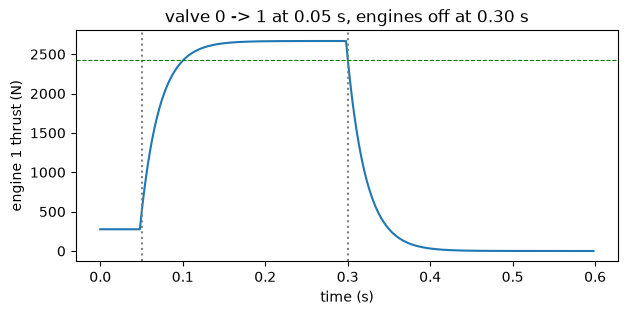

In [3]:
geom = build_geometry(cfg)
eng = EngineBank(cfg, geom)
eng.reset(np.random.default_rng(0), throttle0=(0, 0, 0))
dt, t, T = cfg.sim.physics_dt_s, [], []
for i in range(300):
    time_s = i * dt
    if i == 25:
        eng.command((1, 1, 1))
    if i == 150:
        eng.command((1, 1, 1), engines_off=True)
    T.append(eng.step(dt)[0]); t.append(time_s)
plt.figure(figsize=(7, 3))
plt.plot(t, T); plt.axvline(0.05, ls=":", c="gray"); plt.axvline(0.30, ls=":", c="gray")
plt.axhline(0.9 * cfg.engine.thrust_max_n + 0.1 * cfg.engine.thrust_min_n, ls="--", c="g", lw=0.8)
plt.xlabel("time (s)"); plt.ylabel("engine 1 thrust (N)"); plt.title("valve 0 -> 1 at 0.05 s, engines off at 0.30 s"); plt.show()

## 3. Thrust misalignment: the only steady disturbance
0.044 deg (MSL proxy, S7), random direction each episode. With no attitude control a hovering lander slowly tilts
and spins; with the misalignment switched off it stays level (the CG is fixed on the centre line).

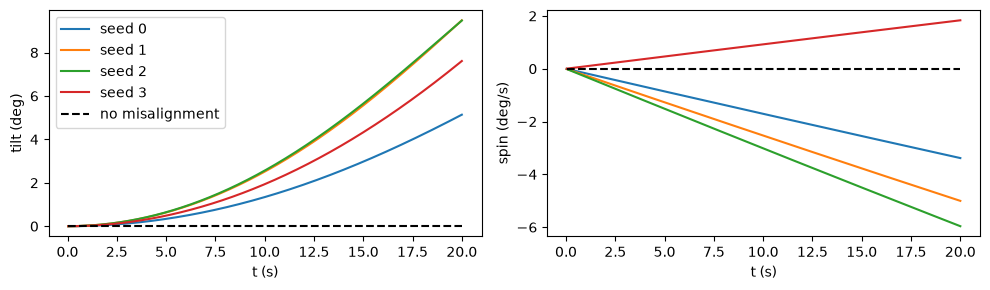

In [4]:
def hover_tilt(overrides, seed, seconds=20.0):
    sim = LanderSim(cfg.with_overrides(overrides))
    sim.reset(seed=seed, initial_state=sim.state_above_ground(300.0))
    ts, tilt, spin = [], [], []
    for _ in range(int(seconds * 25)):
        res = sim.step(Command(sim.hover_trim()))
        ts.append(res.telemetry.t); tilt.append(res.telemetry.tilt_deg); spin.append(res.telemetry.spin_dps)
    return ts, tilt, spin
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
for seed in range(4):
    ts, tilt, spin = hover_tilt({"SIM_SENSOR_NOISE_SCALE": 0.0}, seed)
    ax[0].plot(ts, tilt, label=f"seed {seed}"); ax[1].plot(ts, spin)
ts, tilt, spin = hover_tilt(CLEAN, 0)
ax[0].plot(ts, tilt, "k--", label="no misalignment"); ax[1].plot(ts, spin, "k--")
ax[0].set_ylabel("tilt (deg)"); ax[1].set_ylabel("spin (deg/s)")
for a in ax: a.set_xlabel("t (s)")
ax[0].legend(); plt.tight_layout(); plt.show()

## 4. The dust-storm push
Mars air is thin (0.016 kg/m3, S11): a 17-30 m/s storm pushes the lander sideways with only 5-15 N. Left alone for
30 s that is 0.2-0.7 m/s of drift, up to half of the 1.22 m/s sideways limit. Calm winds (2-10 m/s) are left out:
they move the lander < 0.08 m/s in 30 s.

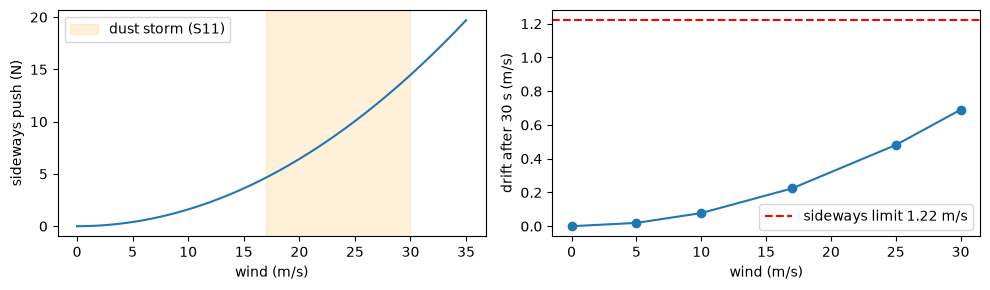

In [5]:
cda, rho = drag_areas(cfg), cfg.mars.air_density_kgpm3
w = np.linspace(0, 35, 141)
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(w, [abs(drag_force_body(np.array([x, 0, 0]), rho, cda)[0]) for x in w])
ax[0].axvspan(*cfg.wind.storm_mps, alpha=0.15, color="orange", label="dust storm (S11)")
ax[0].set_xlabel("wind (m/s)"); ax[0].set_ylabel("sideways push (N)"); ax[0].legend()

def drift(wind):
    sim = LanderSim(cfg.with_overrides({"VIKING_ENGINE_MISALIGN_DEG": 0.0, "SIM_SENSOR_NOISE_SCALE": 0.0}))
    res = sim.reset(initial_state=sim.state_above_ground(300.0), options={"wind_speed_mps": wind})
    for _ in range(750):
        res = sim.step(Command(sim.hover_trim()))
    return float(np.linalg.norm(res.telemetry.vel[:2]))
winds = [0, 5, 10, 17, 25, 30]
ax[1].plot(winds, [drift(x) for x in winds], "o-")
ax[1].axhline(cfg.req.horizontal_speed_mps, c="r", ls="--", label="sideways limit 1.22 m/s")
ax[1].set_xlabel("wind (m/s)"); ax[1].set_ylabel("drift after 30 s (m/s)"); ax[1].legend()
plt.tight_layout(); plt.show()

## 5. Free fall: simulator vs closed form (engines off, no air)

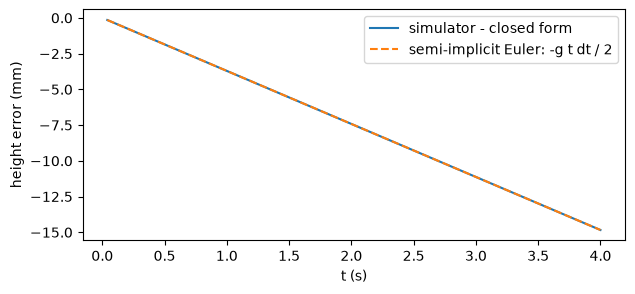

In [6]:
sim = LanderSim(cfg.with_overrides(CLEAN))
st = sim.state_above_ground(200.0, velocity=(0, 0, -5.0))
res = sim.reset(initial_state=st, options={"engines_enabled": False})
z0, g = res.telemetry.cg[2], cfg.mars.gravity_mps2
ts, err = [], []
for _ in range(100):
    res = sim.step(Command())
    t_ = res.telemetry.t
    ts.append(t_); err.append(res.telemetry.cg[2] - (z0 - 5 * t_ - 0.5 * g * t_ ** 2))
plt.figure(figsize=(7, 3)); plt.plot(ts, np.array(err) * 1000, label="simulator - closed form")
plt.plot(ts, -0.5 * g * np.array(ts) * cfg.sim.physics_dt_s * 1000, "--", label="semi-implicit Euler: -g t dt / 2")
plt.xlabel("t (s)"); plt.ylabel("height error (mm)"); plt.legend(); plt.show()

## 6. Propellant: tank vs integral of actual thrust / (Isp g0); mass = dry + propellant

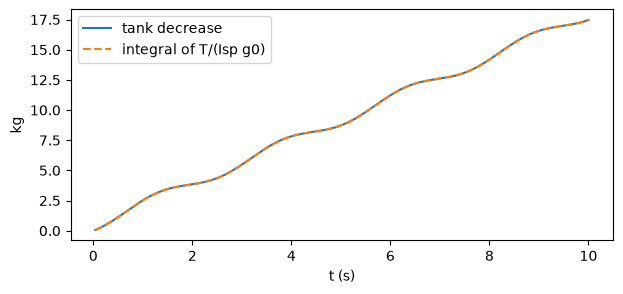

max difference (kg): 2.877698079828406e-13
mass now: 615.64 kg = dry 573.1 + propellant 42.54


In [7]:
sim = LanderSim(cfg)
sim.reset(initial_state=sim.state_above_ground(400.0))
isp_g0 = cfg.engine.isp_s * G0_MPS2
acc = {"kg": 0.0}
def tally(s, k):
    acc["kg"] += s._last_thrust.sum() / isp_g0 * s.dt
tank, integral, tt = [], [], []
m0 = sim.vehicle.propellant
for i in range(250):
    u = 0.35 + 0.3 * math.sin(0.1 * i)
    res = sim.step(Command((u, u, u)), substep_callback=tally)
    tt.append(res.telemetry.t); tank.append(m0 - sim.vehicle.propellant); integral.append(acc["kg"])
plt.figure(figsize=(7, 3)); plt.plot(tt, tank, label="tank decrease"); plt.plot(tt, integral, "--", label="integral of T/(Isp g0)")
plt.xlabel("t (s)"); plt.ylabel("kg"); plt.legend(); plt.show()
print("max difference (kg):", max(abs(a - b) for a, b in zip(tank, integral)))
print("mass now:", round(res.telemetry.mass_kg, 3), "kg = dry", cfg.mass.dry_kg, "+ propellant", round(sim.vehicle.propellant, 3))

## 7. A Viking-like touchdown (scenario `drop`)
6 m up, 2.44 m/s down, thrust = weight; the script cuts the engines at first contact (the agent's job from M2).
The rigid legs rebound a little (about 13 % of the impact speed) before the lander settles.

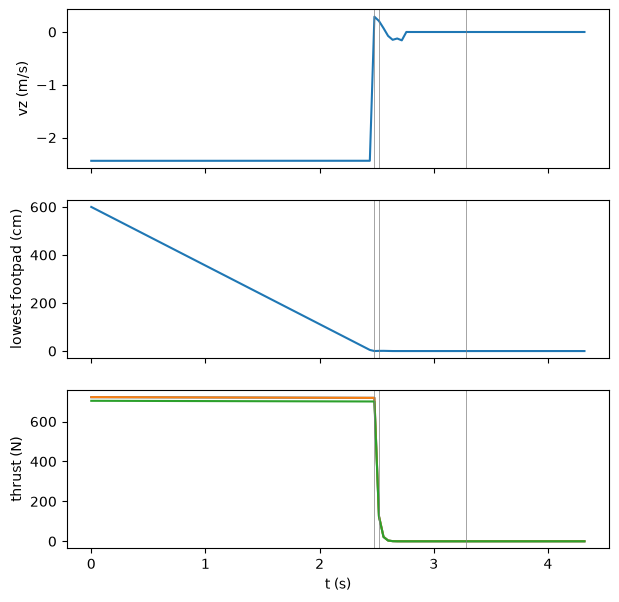

{'touched_down': True, 'first_contact_time': 2.4599999999999507, 'vz_at_contact': 2.4388846112507148, 'vh_at_contact': 0.0027304781159749763, 'tilt_at_contact_deg': 0.07496276168573407, 'leg_broken': False, 'min_stability_m': 0.6890287373822903, 'settled': True, 'settle_time': 3.2519999999998634, 'tipped_over': False, 'body_strike': False, 'propellant_exhausted_airborne': False, 'engines_off': True, 'final_tilt_deg': 0.0, 'final_xy': (0.006408694107754639, -0.009711758477828725)}
criteria: {'vertical_speed': True, 'horizontal_speed': True, 'stable': True, 'no_body_strike': True, 'engines_off': True, 'propellant_left_at_touchdown': True, 'inside_pad_radius': None, 'tilt_within_limit': None} success: True


In [8]:
sim = LanderSim(cfg)
results = run_scenario(sim, make_scenario("drop", sim))
t = [r.telemetry.t for r in results]
fig, ax = plt.subplots(3, 1, figsize=(7, 7), sharex=True)
ax[0].plot(t, [r.telemetry.vz for r in results]); ax[0].set_ylabel("vz (m/s)")
ax[1].plot(t, [r.telemetry.pad_altitude * 100 for r in results]); ax[1].set_ylabel("lowest footpad (cm)")
ax[2].plot(t, [r.telemetry.thrust_n for r in results]); ax[2].set_ylabel("thrust (N)"); ax[2].set_xlabel("t (s)")
for r in results:
    if r.events:
        for a in ax:
            a.axvline(r.telemetry.t, c="gray", lw=0.5)
plt.show()
rep = results[-1].report
print({k: v for k, v in rep.__dict__.items() if k != "criteria"})
print("criteria:", rep.criteria, "success:", rep.success)

## 8. Video of the same scenario (offscreen render, headless)

In [9]:
from IPython.display import Video
from scripts.export_video import main as export_video
out = export_video(["--scenario", "drop", "--out", "runs/videos/notebook_drop.mp4", "--width", "848", "--height", "480"])
Video(str(out), embed=True, width=640)

drop: Viking-like touchdown: 6 m up, 2.44 m/s down, thrust = weight, engines cut on contact -> lands
t = 4.32 s, propellant left 3.20 kg, engines cut
touchdown at 2.46 s: 2.44 m/s down, 0.00 m/s sideways, tilt 0.1 deg
min stability distance 0.689 m, settled: True, tipped over: False, body strike: False
criteria: vertical_speed=True, horizontal_speed=True, stable=True, no_body_strike=True, engines_off=True, propellant_left_at_touchdown=True, inside_pad_radius=n/a (M2), tilt_within_limit=n/a (M2)
RESULT: SUCCESS
wrote 109 frames (4.4 s) to runs\videos\notebook_drop.mp4
